# Cálculo Numérico - Estabilidade e overflow

**Atividade prática II | Dinâmica dos fluidos computacional**

Este notebook resolve integralmente as sete atividades do enunciado: cálculo do critério de estabilidade, testes com `float32` e `float64`, interpretação física, refinamento da malha, comparação com o regime estacionário e conclusão.

## tl;dr

Para a malha de 21 pontos, `Δy = 0,0005 m` e `Δt_max = 0,00125 s`. O caso A (`Δt = 0,001 s`, `r = 0,4`) é estável e permanece fisicamente admissível. O caso B (`Δt = 0,002 s`, `r = 0,8`) é instável: a solução já ultrapassa `1 m/s` no terceiro passo e ocorre overflow posteriormente.

Usar `float64` não elimina a instabilidade; apenas posterga o overflow do passo 121 para o passo 917. Com 41 pontos, o limite cai para `Δt_max = 0,0003125 s`, então `Δt = 0,001 s` é instável e `Δt = 0,0001 s` é estável. A causa é corrigida respeitando `r ≤ 1/2`.

## 1. Contexto e método

O fluido está entre duas placas paralelas separadas por `H = 0,01 m`. A placa em `y = 0` move-se com `U = 1 m/s`, a placa em `y = H` permanece parada e o fluido começa em repouso. Sem gradiente de pressão, o modelo é

\[
\frac{\partial u}{\partial t}=\nu\frac{\partial^2u}{\partial y^2},
\qquad u(0,t)=U,\quad u(H,t)=0.
\]

Aplicamos Euler explícito no tempo e diferença central no espaço:

\[
u_i^{n+1}=u_i^n+r\left(u_{i+1}^n-2u_i^n+u_{i-1}^n\right),
\qquad r=\frac{\nu\Delta t}{\Delta y^2}.
\]

Para este esquema, a condição de estabilidade é `r ≤ 1/2`, ou, equivalentemente, `Δt ≤ Δy²/(2ν)`.

### Hipóteses e critérios

- A solução fisicamente esperada deve satisfazer `0 ≤ u ≤ U`.
- Consideramos overflow quando uma operação de ponto flutuante gera `FloatingPointError` com `over='raise'`.
- Instabilidade é registrada separadamente pela primeira iteração em que `max|u| > U`, mesmo que ainda não exista overflow.
- O perfil estacionário usado na comparação é `u_est(y) = U(1-y/H)`; ele representa o regime final, não o transiente completo.

### 1.1. Parâmetros e implementação

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", message="overflow encountered in power", category=RuntimeWarning)
plt.style.use("seaborn-v0_8-whitegrid")

H = 0.01       # m
nu = 1e-4      # m²/s
U = 1.0        # m/s

def parametros_malha(pontos):
    dy = H / (pontos - 1)
    dt_max = dy**2 / (2 * nu)
    return dy, dt_max

def simular(dt, tipo=np.float32, passos=2000, pontos=21):
    """Executa o esquema explícito e registra falha e perda de admissibilidade."""
    y = np.linspace(0, H, pontos)
    dy = H / (pontos - 1)
    r = tipo(nu * dt / dy**2)
    dois = tipo(2)

    u = np.zeros(pontos, dtype=tipo)
    u[0] = tipo(U)
    tempos = [0.0]
    maximos = [float(np.max(np.abs(u)))]
    primeiro_nao_fisico = None
    falha = None

    with np.errstate(over="raise", invalid="raise"):
        for passo in range(1, passos + 1):
            try:
                novo = u.copy()
                novo[1:-1] = u[1:-1] + r * (
                    u[2:] - dois * u[1:-1] + u[:-2]
                )
            except FloatingPointError:
                falha = passo
                break

            u = novo
            maximo = float(np.max(np.abs(u)))
            tempos.append(passo * dt)
            maximos.append(maximo)
            if primeiro_nao_fisico is None and maximo > U:
                primeiro_nao_fisico = passo

    return {
        "y": y, "u": u, "tempos": tempos, "maximos": maximos,
        "r": float(r), "dt": dt, "tipo": tipo.__name__,
        "falha": falha, "primeiro_nao_fisico": primeiro_nao_fisico,
        "passos_executados": len(tempos) - 1,
    }

dy_21, dt_max_21 = parametros_malha(21)
parametros = pd.DataFrame({
    "parâmetro": ["H", "ν", "U", "pontos", "Δy", "Δt_max"],
    "valor": [H, nu, U, 21, dy_21, dt_max_21],
    "unidade": ["m", "m²/s", "m/s", "-", "m", "s"],
})
parametros

,parâmetro,valor,unidade
0,H,0.01000,m
1,ν,0.00010,m²/s
2,U,1.00000,m/s
3,pontos,21.00000,-
4,Δy,0.00050,m
5,Δt_max,0.00125,s


## 2. Atividade 1 - Verificação da estabilidade

O cálculo abaixo explicita `Δy`, `Δt_max` e `r` para os casos A e B antes da execução da simulação.

In [2]:
casos = pd.DataFrame({
    "caso": ["A", "B"],
    "Δt (s)": [0.001, 0.002],
})
casos["Δy (m)"] = dy_21
casos["Δt_max (s)"] = dt_max_21
casos["r"] = nu * casos["Δt (s)"] / casos["Δy (m)"]**2
casos["coeficiente central (1 - 2r)"] = 1 - 2 * casos["r"]
casos["classificação"] = np.where(casos["r"] <= 0.5, "estável", "instável")
casos

,caso,Δt (s),Δy (m),Δt_max (s),r,coeficiente central (1 - 2r),classificação
0,A,0.001,0.0005,0.00125,0.4,0.2,estável
1,B,0.002,0.0005,0.00125,0.8,-0.6,instável


**Resposta.** O caso A é estável porque `r = 0,4 ≤ 0,5`. O caso B é instável porque `r = 0,8 > 0,5`. No caso B, o coeficiente central vale `1-2r = -0,6`; por isso a atualização deixa de ser uma média ponderada não negativa e pode amplificar oscilações.

## 3. Atividade 2 - Testes de overflow

In [3]:
resultados = {}
for tipo in (np.float32, np.float64):
    for dt in (0.001, 0.002):
        chave = f"{tipo.__name__}, Δt={dt}"
        resultados[chave] = simular(dt, tipo=tipo, passos=2000, pontos=21)

linhas = []
for resultado in resultados.values():
    linhas.append({
        "tipo numérico": resultado["tipo"],
        "Δt (s)": resultado["dt"],
        "r": resultado["r"],
        "classificação": "estável" if resultado["r"] <= 0.5 else "instável",
        "primeiro passo não físico": resultado["primeiro_nao_fisico"] or "-",
        "overflow": "sim" if resultado["falha"] is not None else "não",
        "iteração da falha": resultado["falha"] or "-",
        "passos executados": resultado["passos_executados"],
    })
tabela_testes = pd.DataFrame(linhas)
tabela_testes

,tipo numérico,Δt (s),r,classificação,primeiro passo não físico,overflow,iteração da falha,passos executados
0,float32,0.001,0.4,estável,-,não,-,2000
1,float32,0.002,0.8,instável,3,sim,121,120
2,float64,0.001,0.4,estável,-,não,-,2000
3,float64,0.002,0.8,instável,3,sim,917,916


A tabela mostra a diferença entre instabilidade e overflow: nos dois testes instáveis, a primeira velocidade não física aparece no passo 3, mas o overflow só aparece muito depois. O limite de representação é aproximadamente `3,4×10³⁸` para `float32` e `1,8×10³⁰⁸` para `float64`.

### 3.1. Gráfico da maior velocidade

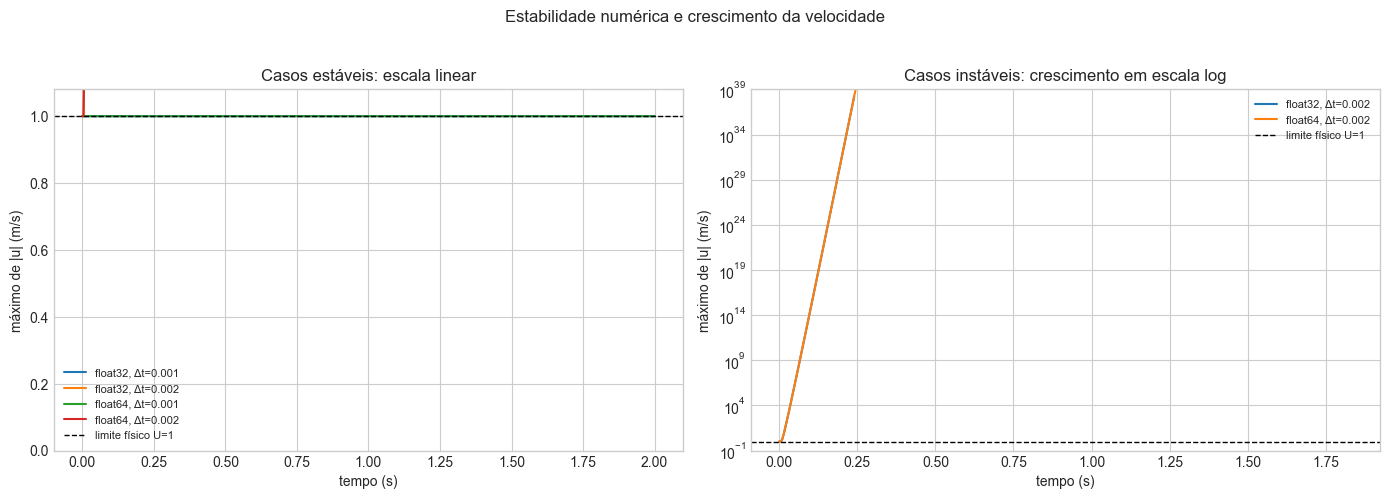

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

for chave, resultado in resultados.items():
    axes[0].plot(resultado["tempos"], resultado["maximos"], label=chave)
axes[0].axhline(U, color="black", linestyle="--", linewidth=1, label="limite físico U=1")
axes[0].set_title("Casos estáveis: escala linear")
axes[0].set_xlabel("tempo (s)")
axes[0].set_ylabel("máximo de |u| (m/s)")
axes[0].set_ylim(0, 1.08)
axes[0].legend(fontsize=8)

for chave, resultado in resultados.items():
    if resultado["r"] > 0.5:
        axes[1].semilogy(resultado["tempos"], resultado["maximos"], label=chave)
axes[1].axhline(U, color="black", linestyle="--", linewidth=1, label="limite físico U=1")
axes[1].set_title("Casos instáveis: crescimento em escala log")
axes[1].set_xlabel("tempo (s)")
axes[1].set_ylabel("máximo de |u| (m/s)")
axes[1].set_ylim(1e-1, 1e39)
axes[1].legend(fontsize=8)

fig.suptitle("Estabilidade numérica e crescimento da velocidade", y=1.03)
fig.tight_layout()
plt.show()

## 4. Atividades 3 e 4 - Interpretação física e tipo numérico

No caso estável, a difusão suaviza o perfil e `max|u|` permanece limitado por `U = 1 m/s`. No caso instável, aparecem oscilações que crescem alternando sinais; portanto, o crescimento observado não é uma aceleração física do fluido. É um erro de discretização causado por `r > 1/2`.

A troca de `float32` por `float64` **não elimina** a instabilidade, porque o valor de `r` é determinado pelo método, pela malha e pelo passo de tempo, não pela faixa de representação. O `float64` apenas suporta números muito maiores: por isso o mesmo crescimento precisa de mais passos para alcançar overflow (`121` contra `917`).

## 5. Atividade 5 - Refinamento da malha

In [5]:
dy_41, dt_max_41 = parametros_malha(41)
refinamento = pd.DataFrame({
    "malha": ["21 pontos", "41 pontos"],
    "Δy (m)": [dy_21, dy_41],
    "Δt_max (s)": [dt_max_21, dt_max_41],
})
refinamento

,malha,Δy (m),Δt_max (s)
0,21 pontos,0.00050,0.001250
1,41 pontos,0.00025,0.000312


Ao dobrar aproximadamente o número de intervalos, `Δy` é reduzido pela metade. Como `Δt_max` depende de `Δy²`, o limite fica quatro vezes menor: `0,0003125 s`.

In [6]:
resultados_41 = {
    "Δt=0,001 s": simular(0.001, tipo=np.float64, passos=2000, pontos=41),
    "Δt=0,0001 s": simular(0.0001, tipo=np.float64, passos=2000, pontos=41),
}
tabela_41 = pd.DataFrame([
    {
        "execução": nome,
        "r": res["r"],
        "classificação": "estável" if res["r"] <= 0.5 else "instável",
        "primeiro passo não físico": res["primeiro_nao_fisico"] or "-",
        "overflow": "sim" if res["falha"] else "não",
        "iteração da falha": res["falha"] or "-",
    }
    for nome, res in resultados_41.items()
])
tabela_41

,execução,r,classificação,primeiro passo não físico,overflow,iteração da falha
0,"Δt=0,001 s",1.60,instável,1,sim,426
1,"Δt=0,0001 s",0.16,estável,-,não,-


**Resposta.** Com 41 pontos e `Δt = 0,001 s`, obtemos `r = 1,6`, portanto a simulação continua instável e ocorre overflow. Reduzindo para `Δt = 0,0001 s`, obtemos `r = 0,16`, que satisfaz o critério; nesse teste não ocorre overflow nem perda da faixa física.

## 6. Atividade 6 - Perfil de velocidade

r = 0.400
tempo simulado = 20.0 s
E = max|u - u_est| = 3.4417e-15 m/s


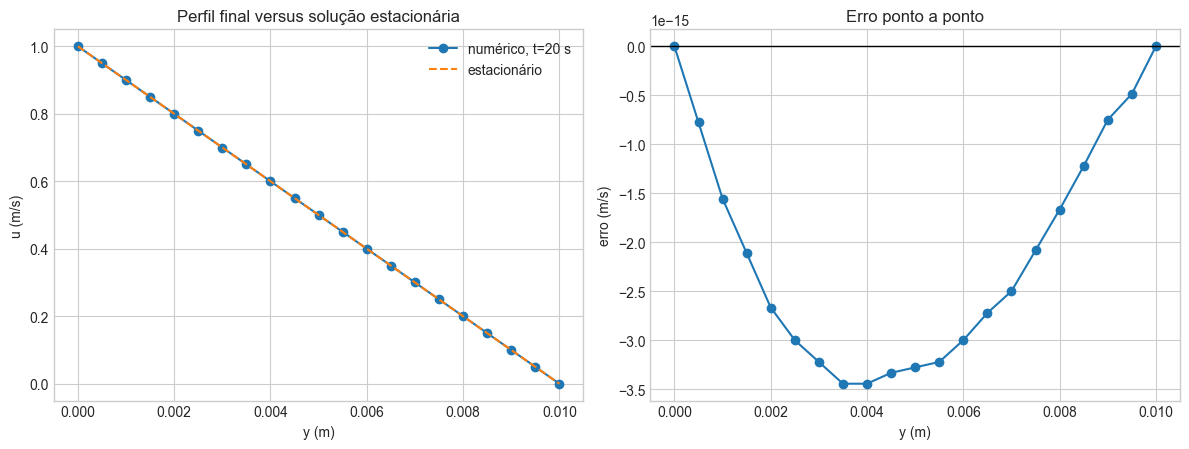

In [7]:
# Execução estável e longa: 20.000 passos de 0,001 s = 20 s.
perfil_final = simular(0.001, tipo=np.float64, passos=20000, pontos=21)
y = perfil_final["y"]
u_final = perfil_final["u"]
u_estacionario = U * (1 - y / H)
erro_maximo = float(np.max(np.abs(u_final - u_estacionario)))

print(f"r = {perfil_final['r']:.3f}")
print(f"tempo simulado = {perfil_final['tempos'][-1]:.1f} s")
print(f"E = max|u - u_est| = {erro_maximo:.4e} m/s")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].plot(y, u_final, "o-", label="numérico, t=20 s")
axes[0].plot(y, u_estacionario, "--", label="estacionário")
axes[0].set_xlabel("y (m)")
axes[0].set_ylabel("u (m/s)")
axes[0].set_title("Perfil final versus solução estacionária")
axes[0].legend()

axes[1].plot(y, u_final - u_estacionario, "o-")
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_xlabel("y (m)")
axes[1].set_ylabel("erro (m/s)")
axes[1].set_title("Erro ponto a ponto")
fig.tight_layout()
plt.show()

**Resposta.** O perfil numérico converge para uma reta decrescente, em excelente concordância com `u_est(y) = U(1-y/H)`. Para `t = 20 s`, o erro máximo calculado é da ordem de `10⁻¹⁵ m/s`, portanto o tempo simulado é mais que suficiente para aproximar o regime estacionário. Em geral, uma simulação curta ainda conteria o transiente e teria erro maior, mesmo usando um esquema estável.

## 7. Conclusão

O refinamento da malha melhora a resolução espacial, mas reduz o passo de tempo permitido: `Δt_max = Δy²/(2ν)`. Se `Δt` for mantido grande após o refinamento, `r` ultrapassa `1/2`, o coeficiente central torna-se negativo e a solução pode oscilar e crescer.

A instabilidade numérica é a causa primária da solução incorreta; o overflow é uma falha posterior de representação. A alteração que corrige a causa é escolher `Δt` de forma que `r ≤ 1/2` (e repetir esse ajuste quando a malha for refinada). Alterar apenas `float32` para `float64` aumenta a faixa numérica, mas não corrige o método.

## Checklist de entrega

- [x] Código executado para a simulação.
- [x] Cálculo de `Δy`, `Δt_max` e `r` para os casos A e B.
- [x] Tabela dos testes com `float32` e `float64`.
- [x] Gráficos da maior velocidade e do perfil final.
- [x] Teste com 41 pontos e novo limite de estabilidade.
- [x] Erro máximo em relação ao perfil estacionário.
- [x] Respostas interpretativas e conclusão.